In [209]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [349]:
df = pd.read_csv('acc_gyr.csv')
df = df[2000:4000]

In [350]:
df.sample(random_state = 11)

,xAcc,yAcc,zAcc,xGyro,yGyro,zGyro,label
2041,8.76,-2.13,-5.06,-15.69,19.78,22.16,rfall


In [351]:
df.describe()

,xAcc,yAcc,zAcc,xGyro,yGyro,zGyro
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,6.031220,-2.930340,1.692255,-6.442190,-2.189060,2.033040
std,3.759239,3.767504,6.620845,38.623679,26.086437,29.911933
min,-28.630000,-29.780000,-22.170000,-379.090000,-335.330000,-161.990000
25%,4.520000,-5.290000,-4.550000,-16.360000,-5.250000,-8.075000
50%,5.990000,-2.680000,5.515000,-1.710000,0.240000,-0.150000
75%,7.320000,-0.790000,7.250000,9.920000,5.567500,12.035000
max,39.240000,22.210000,24.770000,191.890000,117.860000,186.830000


In [352]:
df.columns

Index(['xAcc', 'yAcc', 'zAcc', 'xGyro', 'yGyro', 'zGyro', 'label'], dtype='object')

In [353]:
df.describe()

,xAcc,yAcc,zAcc,xGyro,yGyro,zGyro
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,6.031220,-2.930340,1.692255,-6.442190,-2.189060,2.033040
std,3.759239,3.767504,6.620845,38.623679,26.086437,29.911933
min,-28.630000,-29.780000,-22.170000,-379.090000,-335.330000,-161.990000
25%,4.520000,-5.290000,-4.550000,-16.360000,-5.250000,-8.075000
50%,5.990000,-2.680000,5.515000,-1.710000,0.240000,-0.150000
75%,7.320000,-0.790000,7.250000,9.920000,5.567500,12.035000
max,39.240000,22.210000,24.770000,191.890000,117.860000,186.830000


In [354]:
df.shape

(2000, 7)

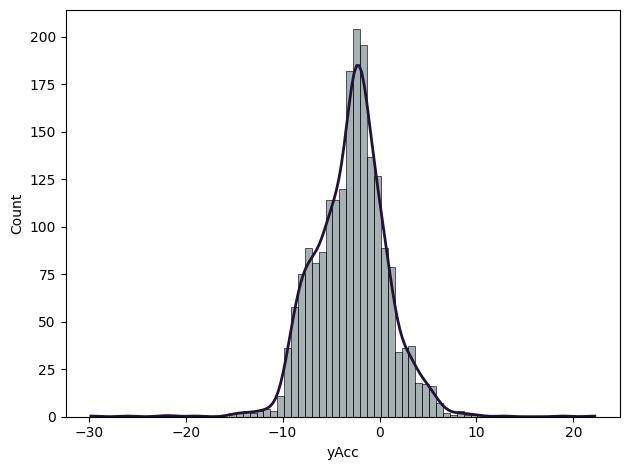

In [355]:
ax = sns.histplot(
    data=df,
    x="yAcc",
    color="#4f646f",
    kde=True
)
plt.tight_layout()

# Change only the KDE curve
ax.lines[-1].set_color("#201335")
ax.lines[-1].set_linewidth(2)

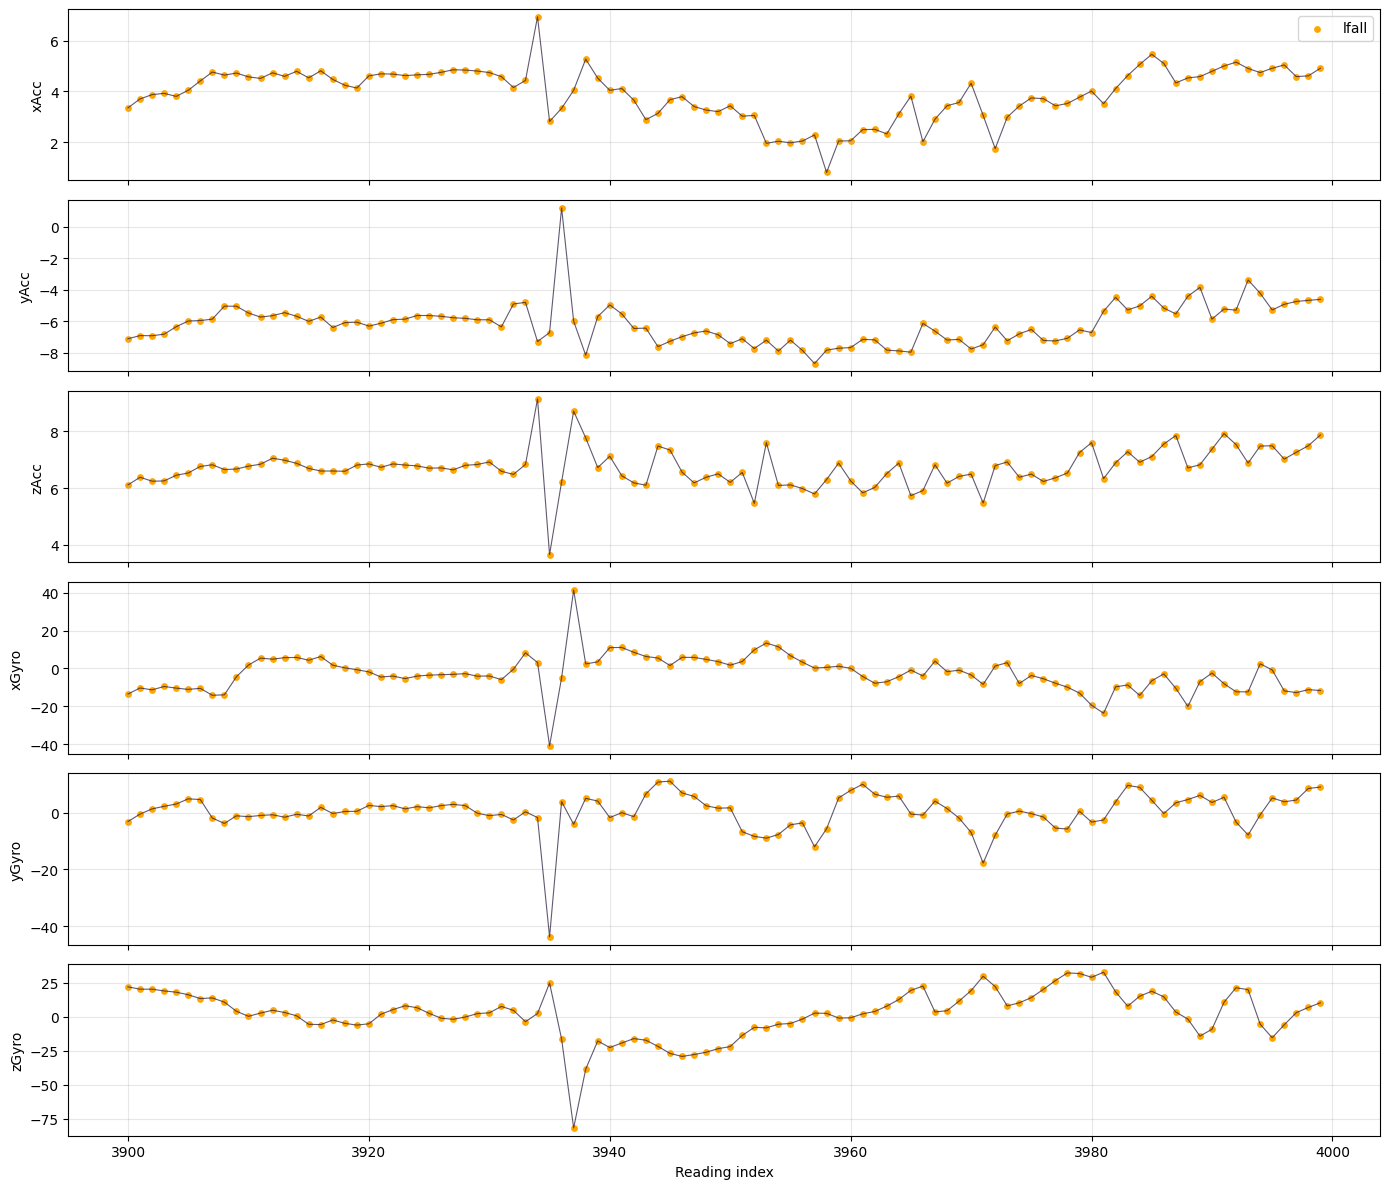

In [356]:
sensor_cols = [
    "xAcc", "yAcc", "zAcc",
    "xGyro", "yGyro", "zGyro"
]

colors = {
    "fall": "red",
    "lfall": "orange",
    "rfall": "purple",
    "light": "gold",
    "sit": "green",
    "step": "blue",
    "walk": "cyan"
}

sample = df.iloc[1900:3500]

fig, axes = plt.subplots(6, 1, figsize=(14, 12), sharex=True)

for ax, col in zip(axes, sensor_cols):
    # Continuous line
    ax.plot(sample.index, sample[col], color="#201335",
            linewidth=0.8, alpha=0.7)

    # Exact color for every reading point
    for label, group in sample.groupby("label", sort=False):
        ax.scatter(
            group.index,
            group[col],
            color=colors.get(label, "black"),
            s=15,
            label=label
        )

    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)

axes[0].legend(loc="upper right", ncol=4)
axes[-1].set_xlabel("Reading index")

plt.tight_layout()
plt.show()

# Applying Z - Score

In [357]:
df['yAcc'].describe()

count    2000.000000
mean       -2.930340
std         3.767504
min       -29.780000
25%        -5.290000
50%        -2.680000
75%        -0.790000
max        22.210000
Name: yAcc, dtype: float64

In [358]:
print("Mean value of yAcc",df['yAcc'].mean())
print("Std value of yAcc",df['yAcc'].std())
print("Min value of yAcc",df['yAcc'].min())
print("Max value of yAcc",df['yAcc'].max())

Mean value of yAcc -2.93034
Std value of yAcc 3.767503912043573
Min value of yAcc -29.78
Max value of yAcc 22.21


In [359]:
low = df['yAcc'].mean() - 3*df['yAcc'].std()
low

np.float64(-14.23285173613072)

In [360]:
high = df['yAcc'].mean() + 3*df['yAcc'].std()
high

np.float64(8.37217173613072)

# Trimming

In [361]:
new_df = df[(df['yAcc'] > low) & (df['yAcc'] < high)]
new_df

,xAcc,yAcc,zAcc,xGyro,yGyro,zGyro,label
2000,8.38,-1.40,-5.06,-22.09,-7.63,-5.31,rfall
2001,7.84,-1.91,-4.92,-18.19,-9.77,-5.74,rfall
2002,7.70,-2.17,-4.71,-14.40,-7.81,-5.19,rfall
2003,7.97,-1.99,-4.71,-12.45,-3.60,0.67,rfall
2004,8.41,-1.94,-4.39,-7.08,-3.30,-1.16,rfall
...,...,...,...,...,...,...,...
3995,4.91,-5.28,7.49,-0.79,5.19,-15.38,lfall
3996,5.04,-4.92,7.02,-11.84,3.85,-5.80,lfall
3997,4.58,-4.74,7.26,-12.76,4.46,3.11,lfall
3998,4.61,-4.67,7.49,-11.17,8.54,6.96,lfall


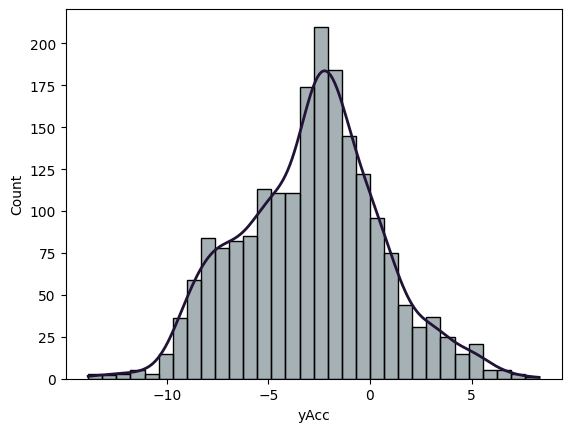

In [362]:
ax = sns.histplot(
    data=new_df,
    x="yAcc",
    color="#4f646f",
    kde=True
)

# Change only the KDE curve
ax.lines[-1].set_color("#201335")
ax.lines[-1].set_linewidth(2)



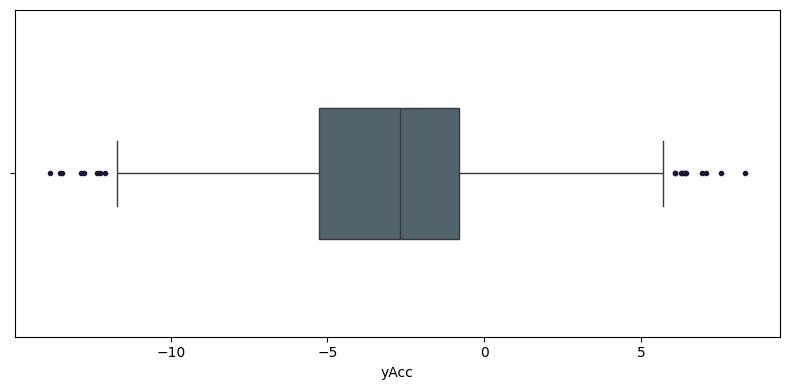

In [363]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=new_df,
    x="yAcc",
    color="#4f646f",
    width=0.4,
    flierprops={
        "marker": "o",
        "markerfacecolor": "#201335",
        "markeredgecolor": "#201335",
        "markersize": 3
    }
)

plt.tight_layout()
plt.show()

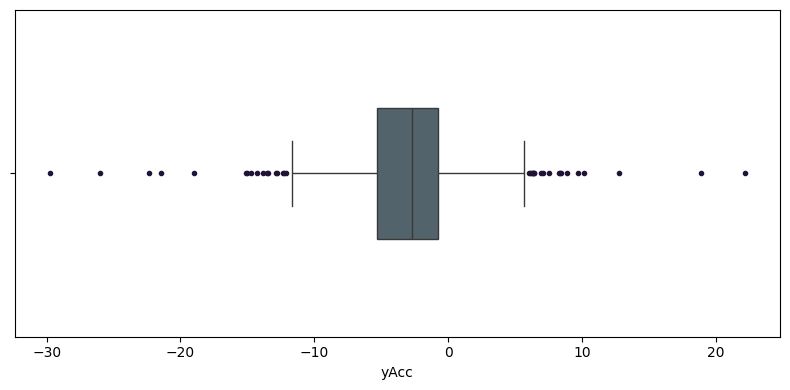

In [364]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df,
    x="yAcc",
    color="#4f646f",
    width=0.4,
    flierprops={
        "marker": "o",
        "markerfacecolor": "#201335",
        "markeredgecolor": "#201335",
        "markersize": 3
    }
)

plt.tight_layout()
plt.show()

# Capping

In [365]:
df['new_yAcc'] = np.where((df['yAcc'] < low), low, np.where((df['yAcc'] > high),high,df['yAcc']))
df.sample()

,xAcc,yAcc,zAcc,xGyro,yGyro,zGyro,label,new_yAcc
2187,5.9,-3.66,7.38,10.01,-1.1,1.95,rfall,-3.66


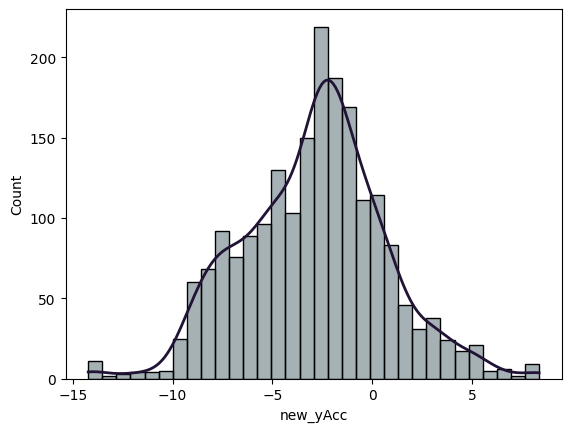

In [367]:
ax = sns.histplot(
    data=df,
    x="new_yAcc",
    color="#4f646f",
    kde=True
)

# Change only the KDE curve
ax.lines[-1].set_color("#201335")
ax.lines[-1].set_linewidth(2)



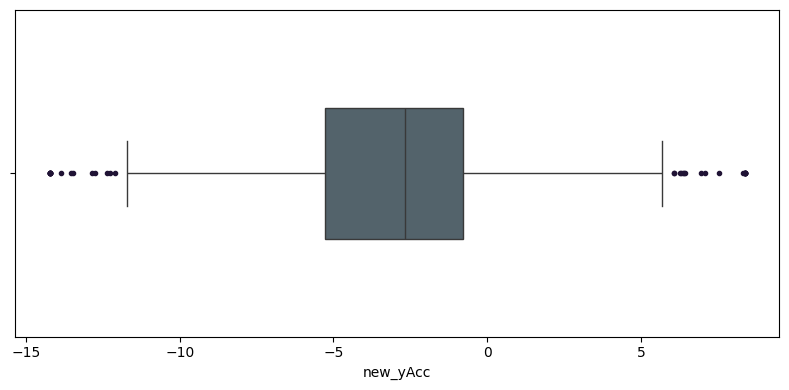

In [368]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df,
    x="new_yAcc",
    color="#4f646f",
    width=0.4,
    flierprops={
        "marker": "o",
        "markerfacecolor": "#201335",
        "markeredgecolor": "#201335",
        "markersize": 3
    }
)

plt.tight_layout()
plt.show()